##1.  Import library

In [123]:
import os
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, roc_auc_score, classification_report, confusion_matrix, average_precision_score, precision_score, recall_score, f1_score, accuracy_score

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit

import joblib

## 2. Download Dataset

In [ ]:
datasetPath = Path("data")
datasetPath.mkdir(parents=True, exist_ok=True)

subprocess.run([
    "kaggle",
    "datasets",
    "download",
    "-d",
    "sgpjesus/bank-account-fraud-dataset-neurips-2022",
    "-p",
    str(datasetPath),
    "--force"
], check=True)

CompletedProcess(args=['kaggle', 'datasets', 'download', '-d', 'sgpjesus/bank-account-fraud-dataset-neurips-2022', '-p', 'data', '--force'], returncode=0)

## 3. Extract Dataset

In [ ]:
zipPath = next(datasetPath.glob("*.zip"))

with zipfile.ZipFile(zipPath, "r") as zipFile:
    zipFile.extractall(datasetPath)

zipPath.unlink()

## 4. Inspect Dataset Files

In [ ]:
datasetFiles = [
    {
        "fileName": file.name,
        "filePath": str(file),
        "sizeMB": round(file.stat().st_size / (1024 ** 2), 2)
    }
    for file in datasetPath.rglob("*")
    if file.is_file()
]

pd.DataFrame(datasetFiles)

,fileName,filePath,sizeMB
0,Base.csv,data/Base.csv,203.54
1,Variant I.csv,data/Variant I.csv,203.51
2,Variant IV.csv,data/Variant IV.csv,203.65
3,Variant II.csv,data/Variant II.csv,203.65
4,Variant V.csv,data/Variant V.csv,240.53
5,Variant III.csv,data/Variant III.csv,240.52


## 5. Load Dataset

In [ ]:
datasetFilePath = datasetPath / "Base.csv"

data = pd.read_csv(datasetFilePath)

data.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## 6. Dataset Overview

In [ ]:
print(f"Dataset shape: {data.shape}")
print(f"Total columns: {data.shape[1]}")
print(f"Total records: {data.shape[0]}")

data.info()

Dataset shape: (1000000, 32)
Total columns: 32
Total records: 1000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                      

## 7. Data Quality Check

In [ ]:
missingValues = pd.DataFrame({
    "missingCount": data.isnull().sum(),
    "missingPercentage": (data.isnull().mean() * 100).round(2)
})

missingValues.sort_values("missingCount", ascending=False)

,missingCount,missingPercentage
fraud_bool,0,0.0
income,0,0.0
name_email_similarity,0,0.0
prev_address_months_count,0,0.0
current_address_months_count,0,0.0
customer_age,0,0.0
days_since_request,0,0.0
intended_balcon_amount,0,0.0
payment_type,0,0.0
zip_count_4w,0,0.0


In [ ]:
duplicateCount = data.duplicated().sum()

print(f"Duplicate records: {duplicateCount}")

Duplicate records: 0


In [ ]:
targetDistribution = pd.DataFrame({
    "count": data["fraud_bool"].value_counts(),
    "percentage": (data["fraud_bool"].value_counts(normalize=True) * 100).round(2)
})

targetDistribution

,count,percentage
fraud_bool,,
0,988971,98.9
1,11029,1.1


In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
fraud_bool,1000000.0,0.011029,0.104438,0.000000e+00,0.000000,0.000000,0.000000,1.000000
income,1000000.0,0.562696,0.290343,1.000000e-01,0.300000,0.600000,0.800000,0.900000
name_email_similarity,1000000.0,0.493694,0.289125,1.434550e-06,0.225216,0.492153,0.755567,0.999999
prev_address_months_count,1000000.0,16.718568,44.046230,-1.000000e+00,-1.000000,-1.000000,12.000000,383.000000
current_address_months_count,1000000.0,86.587867,88.406599,-1.000000e+00,19.000000,52.000000,130.000000,428.000000
customer_age,1000000.0,33.689080,12.025799,1.000000e+01,20.000000,30.000000,40.000000,90.000000
days_since_request,1000000.0,1.025705,5.381835,4.036860e-09,0.007193,0.015176,0.026331,78.456904
intended_balcon_amount,1000000.0,8.661499,20.236155,-1.553055e+01,-1.181488,-0.830507,4.984176,112.956928
zip_count_4w,1000000.0,1572.692049,1005.374565,1.000000e+00,894.000000,1263.000000,1944.000000,6700.000000
velocity_6h,1000000.0,5665.296605,3009.380665,-1.706031e+02,3436.365848,5319.769349,7680.717827,16715.565404


In [ ]:
data.describe(include="object").T

,count,unique,top,freq
payment_type,1000000,5,AB,370554
employment_status,1000000,7,CA,730252
housing_status,1000000,7,BC,372143
source,1000000,2,INTERNET,992952
device_os,1000000,5,other,342728


## 8. Filter Dataset by Month

In [ ]:
data = data[data["month"].between(0, 3)].copy()

print(f"Dataset shape: {data.shape}")
print("\nMonth distribution:")
print(data["month"].value_counts().sort_index())

Dataset shape: (547975, 32)

Month distribution:
month
0    132440
1    127620
2    136979
3    150936
Name: count, dtype: int64


## 9. Target Distribution After Filtering

In [ ]:
targetDistribution = pd.DataFrame({
    "count": data["fraud_bool"].value_counts(),
    "percentage": (data["fraud_bool"].value_counts(normalize=True) * 100).round(2)
})

targetDistribution

,count,percentage
fraud_bool,,
0,542687,99.03
1,5288,0.97


## 10. Feature Analysis

In [ ]:
featureAnalysis = pd.DataFrame({
    "dataType": data.dtypes,
    "uniqueValues": data.nunique(),
    "missingValues": data.isnull().sum()
})

featureAnalysis.sort_values("uniqueValues", ascending=True)

,dataType,uniqueValues,missingValues
device_fraud_count,int64,1,0
fraud_bool,int64,2,0
keep_alive_session,int64,2,0
foreign_request,int64,2,0
phone_home_valid,int64,2,0
has_other_cards,int64,2,0
email_is_free,int64,2,0
source,object,2,0
phone_mobile_valid,int64,2,0
device_distinct_emails_8w,int64,4,0


## 11. Numerical Feature Distribution

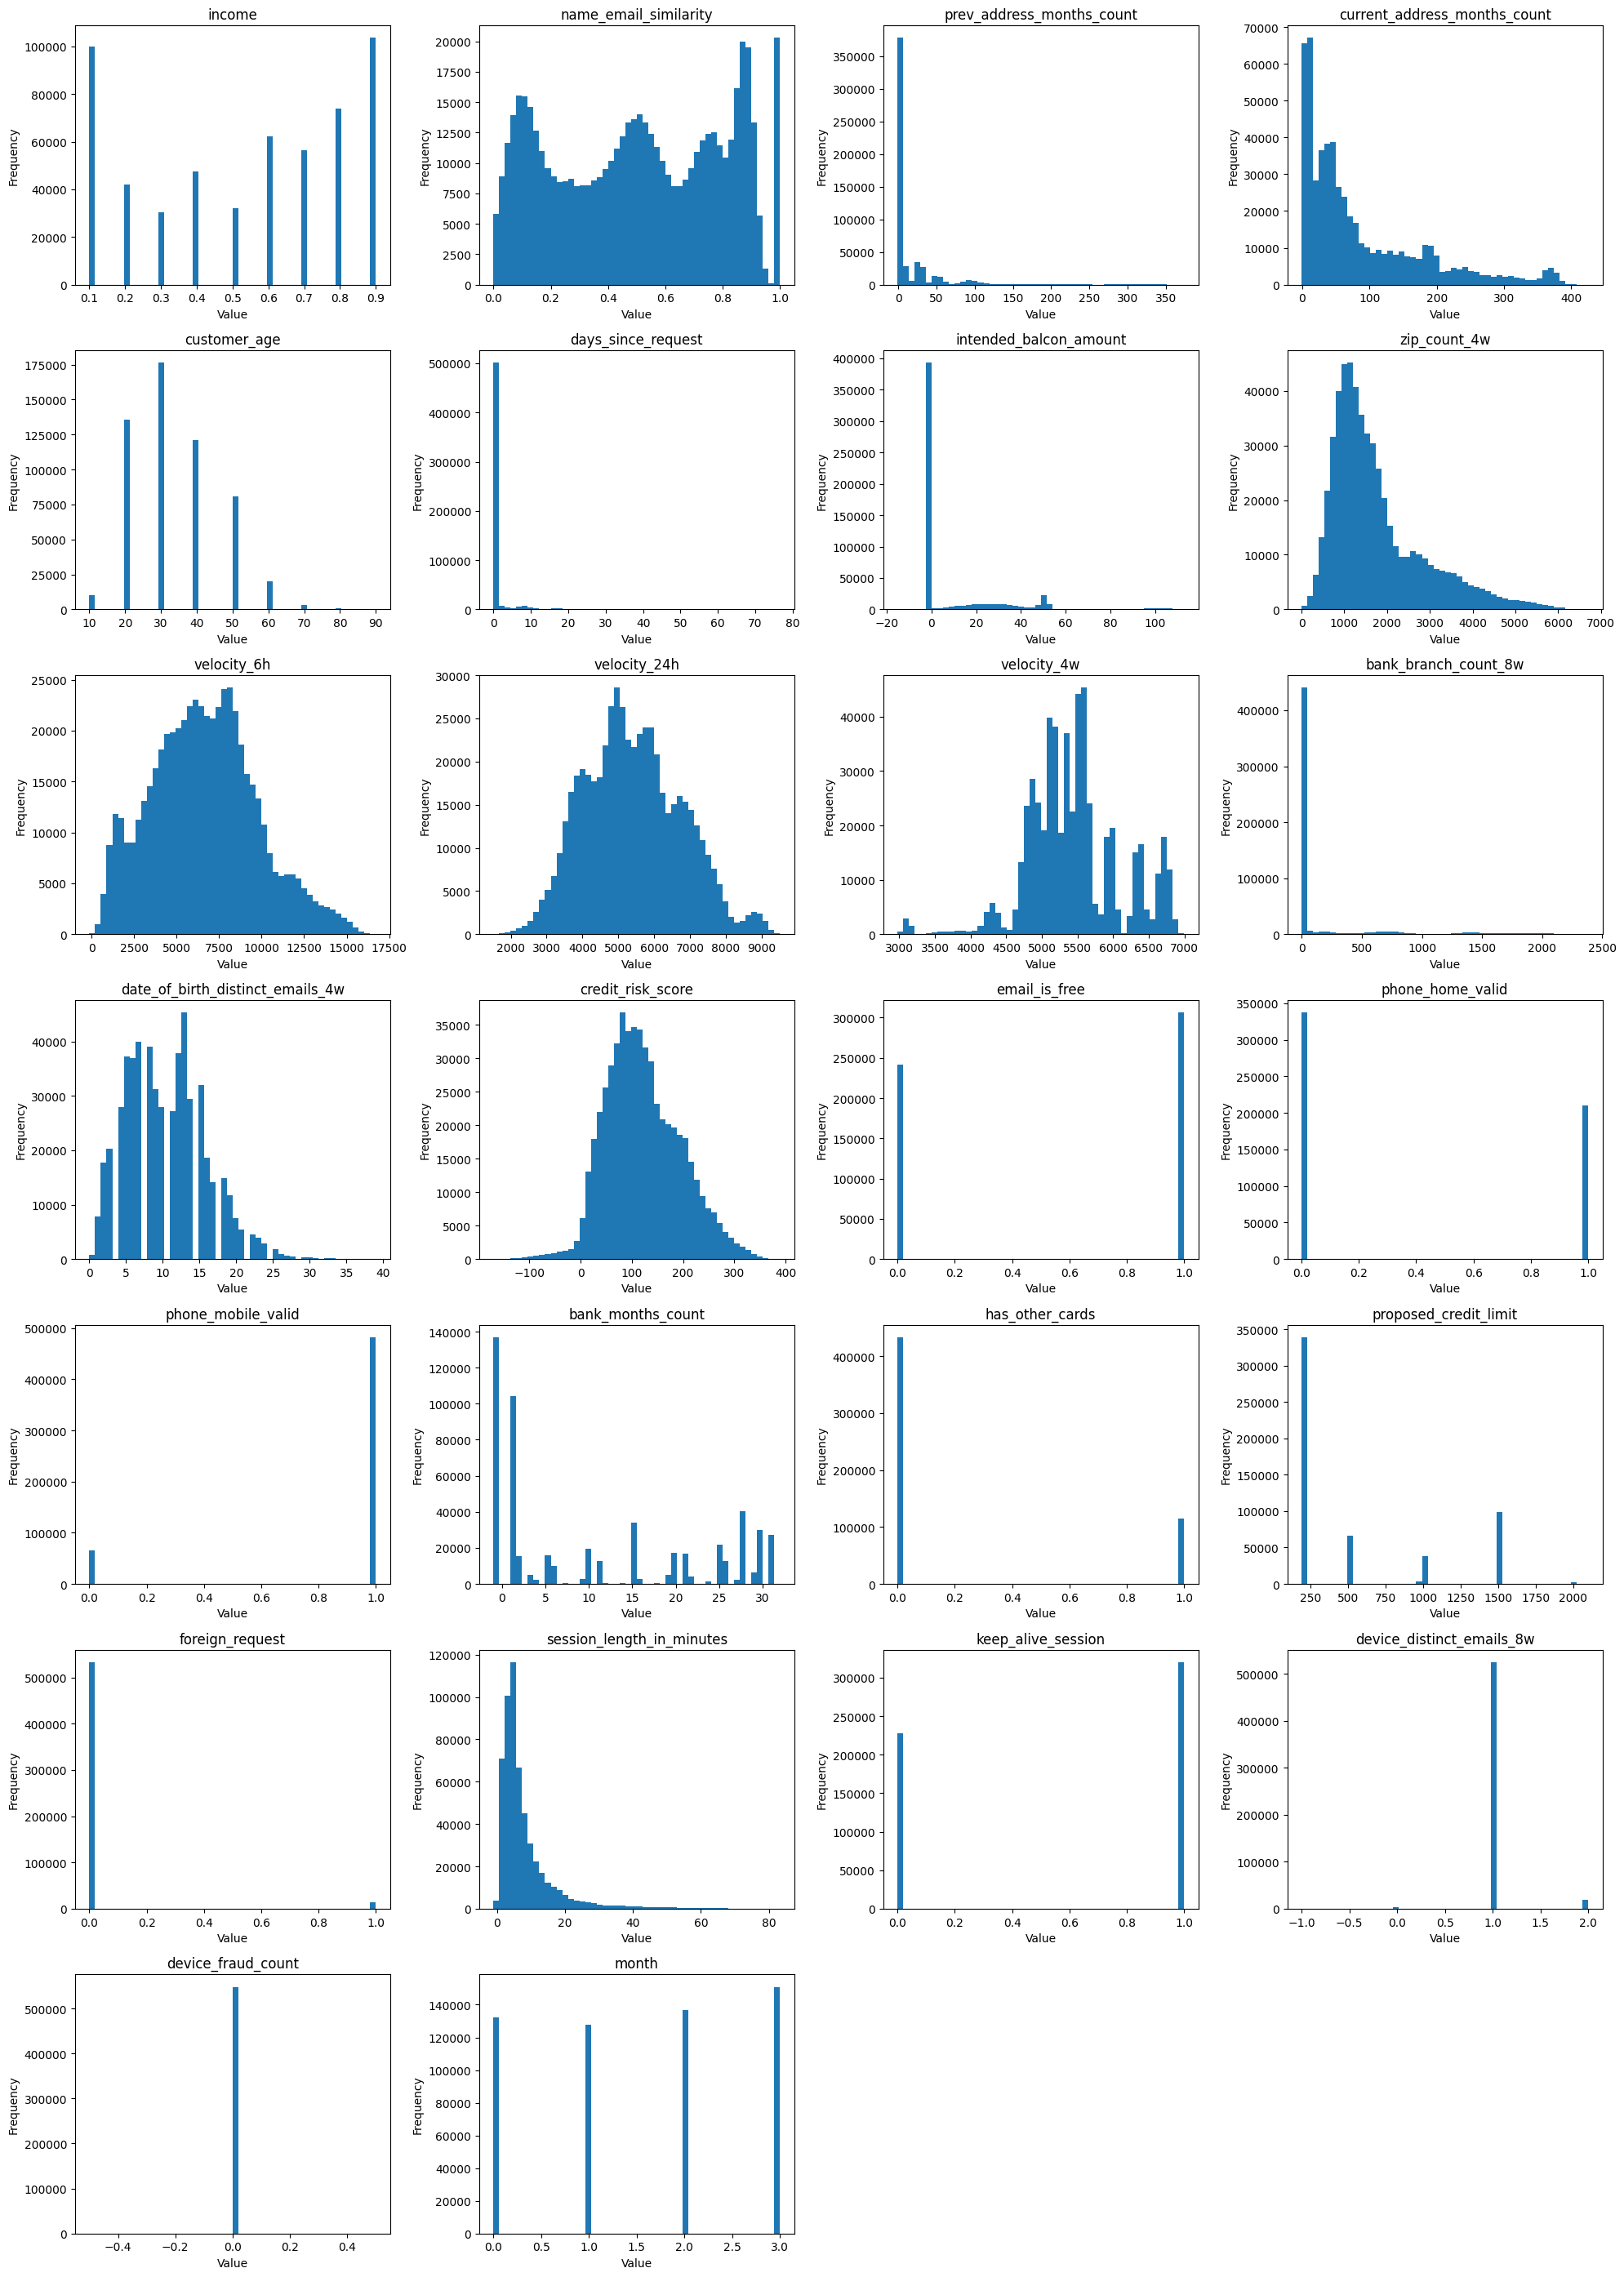

In [ ]:
numericFeatures = data.select_dtypes(include=np.number).columns.drop("fraud_bool")

nCols = 4
nRows = int(np.ceil(len(numericFeatures) / nCols))

fig, axes = plt.subplots(nRows, nCols, figsize=(20, nRows * 4))
axes = axes.flatten()

for i, feature in enumerate(numericFeatures):
    axes[i].hist(data[feature], bins=50)
    axes[i].set_title(feature)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for i in range(len(numericFeatures), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## 12. Categorical Feature Distribution

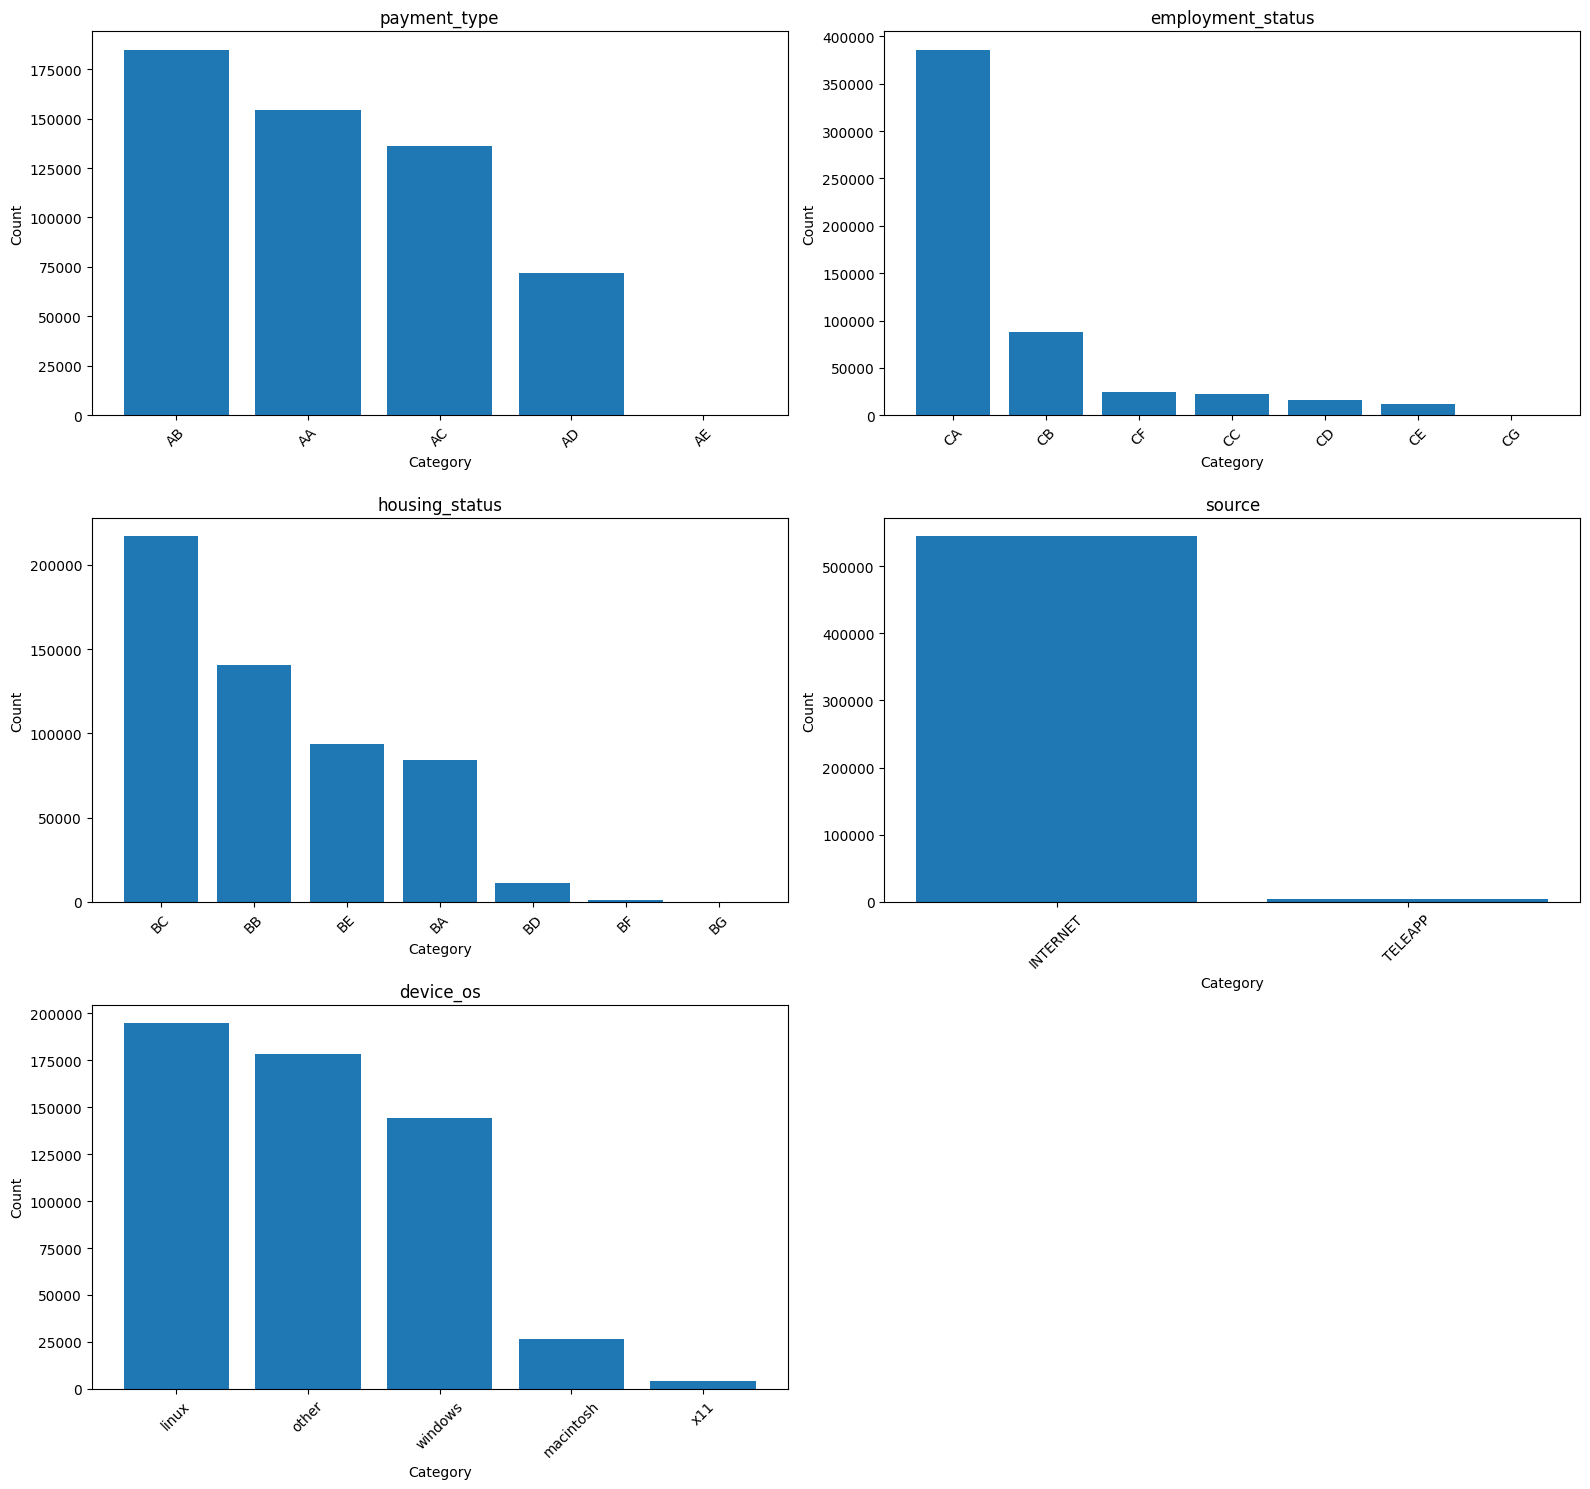

In [ ]:
categoricalFeatures = data.select_dtypes(include="object").columns

nCols = 2
nRows = int(np.ceil(len(categoricalFeatures) / nCols))

fig, axes = plt.subplots(nRows, nCols, figsize=(16, nRows * 5))
axes = axes.flatten()

for i, feature in enumerate(categoricalFeatures):
    categoryCounts = data[feature].value_counts()

    axes[i].bar(categoryCounts.index.astype(str), categoryCounts.values)
    axes[i].set_title(feature)
    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

for i in range(len(categoricalFeatures), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## 13. Check Special Values.

In [ ]:
numericFeatures = data.select_dtypes(include=np.number).columns.drop("fraud_bool")

specialValueSummary = pd.DataFrame({
    "count": (data[numericFeatures] == -1).sum(),
    "percentage": ((data[numericFeatures] == -1).mean() * 100).round(2)
})

specialValueSummary = specialValueSummary[
    specialValueSummary["count"] > 0
].sort_values("count", ascending=False)

print(specialValueSummary.to_string())

                               count  percentage
prev_address_months_count     377557       68.90
bank_months_count             136894       24.98
current_address_months_count    2309        0.42
session_length_in_minutes        995        0.18
credit_risk_score                406        0.07
device_distinct_emails_8w        226        0.04


## 14. Special Values vs Fraud Distribution

In [ ]:
specialValueFeatures = [
    "prev_address_months_count",
    "bank_months_count",
    "current_address_months_count",
    "session_length_in_minutes",
    "credit_risk_score",
    "device_distinct_emails_8w"
]

specialValueResults = []

for feature in specialValueFeatures:
    for hasSpecialValue, group in data.groupby(data[feature] == -1):
        specialValueResults.append({
            "feature": feature,
            "valueType": "-1" if hasSpecialValue else "Other",
            "count": len(group),
            "fraudCount": group["fraud_bool"].sum(),
            "fraudRate": round(group["fraud_bool"].mean() * 100, 3)
        })

specialValueAnalysis = pd.DataFrame(specialValueResults)

specialValueAnalysis

,feature,valueType,count,fraudCount,fraudRate
0,prev_address_months_count,Other,170418,462,0.271
1,prev_address_months_count,-1,377557,4826,1.278
2,bank_months_count,Other,411081,3367,0.819
3,bank_months_count,-1,136894,1921,1.403
4,current_address_months_count,Other,545666,5281,0.968
5,current_address_months_count,-1,2309,7,0.303
6,session_length_in_minutes,Other,546980,5279,0.965
7,session_length_in_minutes,-1,995,9,0.905
8,credit_risk_score,Other,547569,5288,0.966
9,credit_risk_score,-1,406,0,0.000


## 15. Feature Correlation Analysis.

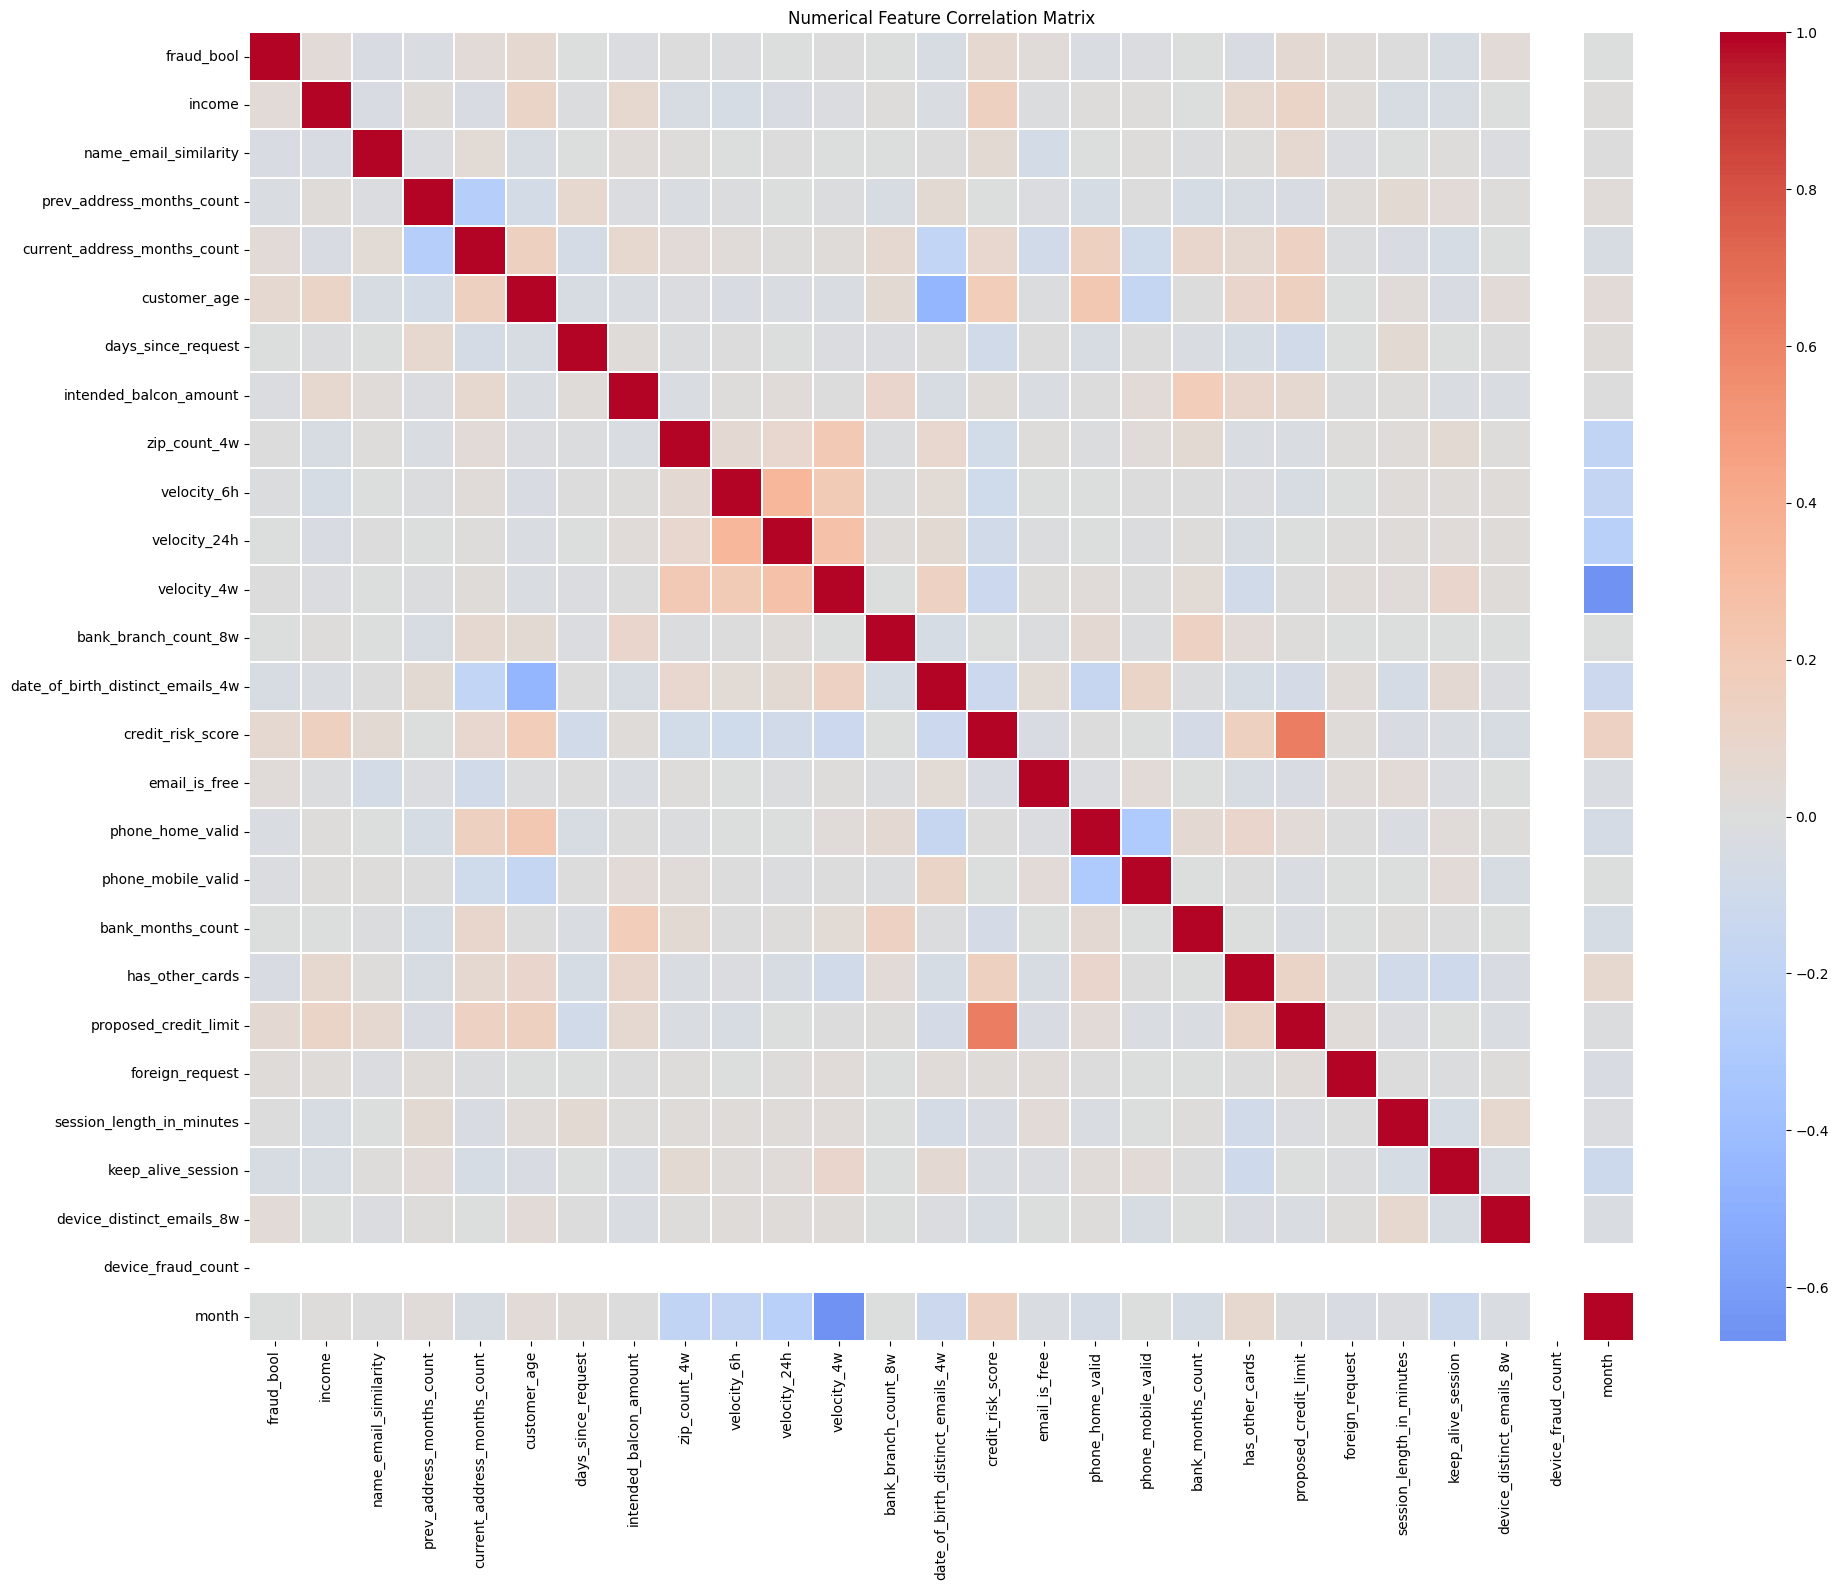

In [ ]:
numericFeatures = data.select_dtypes(include=np.number).columns

correlationMatrix = data[numericFeatures].corr()

plt.figure(figsize=(20, 16))
sns.heatmap(
    correlationMatrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 16. Categorical Feature vs Fraud Distribution

In [ ]:
categoricalFeatures = data.select_dtypes(include="object").columns

categoricalFraudResults = []

for feature in categoricalFeatures:
    categoryAnalysis = data.groupby(feature)["fraud_bool"].agg(
        count="count",
        fraudCount="sum",
        fraudRate="mean"
    )

    categoryAnalysis["fraudRate"] = (categoryAnalysis["fraudRate"] * 100).round(3)
    categoryAnalysis["feature"] = feature
    categoryAnalysis["category"] = categoryAnalysis.index

    categoricalFraudResults.append(
        categoryAnalysis.reset_index(drop=True)
    )

categoricalFraudAnalysis = pd.concat(categoricalFraudResults, ignore_index=True)

categoricalFraudAnalysis = categoricalFraudAnalysis[
    ["feature", "category", "count", "fraudCount", "fraudRate"]
]

categoricalFraudAnalysis

,feature,category,count,fraudCount,fraudRate
0,payment_type,AA,154560,803,0.520
1,payment_type,AB,184880,1859,1.006
2,payment_type,AC,136222,1974,1.449
3,payment_type,AD,72115,651,0.903
4,payment_type,AE,198,1,0.505
5,employment_status,CA,386094,4114,1.066
6,employment_status,CB,88252,528,0.598
7,employment_status,CC,21920,502,2.290
8,employment_status,CD,15762,70,0.444
9,employment_status,CE,11478,28,0.244


## 17. Fraud Distribution by Month

In [ ]:
monthlyFraudAnalysis = data.groupby("month")["fraud_bool"].agg(
    totalApplications="count",
    fraudCount="sum",
    fraudRate="mean"
)

monthlyFraudAnalysis["nonFraudCount"] = (
    monthlyFraudAnalysis["totalApplications"] - monthlyFraudAnalysis["fraudCount"]
)

monthlyFraudAnalysis["fraudRate"] = (
    monthlyFraudAnalysis["fraudRate"] * 100
).round(3)

monthlyFraudAnalysis = monthlyFraudAnalysis[
    ["totalApplications", "nonFraudCount", "fraudCount", "fraudRate"]
]

print(monthlyFraudAnalysis.to_string())

       totalApplications  nonFraudCount  fraudCount  fraudRate
month                                                         
0                 132440         130940        1500      1.133
1                 127620         126422        1198      0.939
2                 136979         135781        1198      0.875
3                 150936         149544        1392      0.922


## 18. Chronological Data Splitting

In [ ]:
trainData = data[data["month"].isin([0, 1])].copy()
validationData = data[data["month"] == 2].copy()
testData = data[data["month"] == 3].copy()

print(f"Training dataset: {trainData.shape}")
print(f"Validation dataset: {validationData.shape}")
print(f"Testing dataset: {testData.shape}")

Training dataset: (260060, 32)
Validation dataset: (136979, 32)
Testing dataset: (150936, 32)


In [ ]:
splitSummary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Testing"],
    "month": ["0-1", "2", "3"],
    "totalRecords": [
        len(trainData),
        len(validationData),
        len(testData)
    ],
    "fraudCount": [
        trainData["fraud_bool"].sum(),
        validationData["fraud_bool"].sum(),
        testData["fraud_bool"].sum()
    ],
    "fraudRate": [
        trainData["fraud_bool"].mean() * 100,
        validationData["fraud_bool"].mean() * 100,
        testData["fraud_bool"].mean() * 100
    ]
})

splitSummary["fraudRate"] = splitSummary["fraudRate"].round(3)

print(splitSummary.to_string(index=False))

   dataset month  totalRecords  fraudCount  fraudRate
  Training   0-1        260060        2698      1.037
Validation     2        136979        1198      0.875
   Testing     3        150936        1392      0.922


## 19. Prepare Features and Target

In [ ]:
targetColumn = "fraud_bool"

excludedColumns = [targetColumn, "month", "device_fraud_count"]

featureColumns = [
    column for column in data.columns
    if column not in excludedColumns
]

numericFeatures = data[featureColumns].select_dtypes(include=np.number).columns.tolist()
categoricalFeatures = data[featureColumns].select_dtypes(include="object").columns.tolist()

print(f"Total features: {len(featureColumns)}")
print(f"Numerical features: {len(numericFeatures)}")
print(f"Categorical features: {len(categoricalFeatures)}")

print("\nNumerical Features:")
print(numericFeatures)

print("\nCategorical Features:")
print(categoricalFeatures)

Total features: 29
Numerical features: 24
Categorical features: 5

Numerical Features:
['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'credit_risk_score', 'email_is_free', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'session_length_in_minutes', 'keep_alive_session', 'device_distinct_emails_8w']

Categorical Features:
['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']


In [ ]:
XTrain = trainData[featureColumns].copy()
yTrain = trainData[targetColumn].copy()

XValidation = validationData[featureColumns].copy()
yValidation = validationData[targetColumn].copy()

XTest = testData[featureColumns].copy()
yTest = testData[targetColumn].copy()

print(f"XTrain: {XTrain.shape} | yTrain: {yTrain.shape}")
print(f"XValidation: {XValidation.shape} | yValidation: {yValidation.shape}")
print(f"XTest: {XTest.shape} | yTest: {yTest.shape}")

XTrain: (260060, 29) | yTrain: (260060,)
XValidation: (136979, 29) | yValidation: (136979,)
XTest: (150936, 29) | yTest: (150936,)


## 20. Build Preprocessing Pipeline

In [ ]:
treePreprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numericFeatures),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categoricalFeatures)
    ],
    remainder="drop"
)

In [ ]:
linearPreprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numericFeatures),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categoricalFeatures)
    ],
    remainder="drop"
)

In [ ]:
XTrainTreeProcessed = treePreprocessor.fit_transform(XTrain)
XValidationTreeProcessed = treePreprocessor.transform(XValidation)
XTestTreeProcessed = treePreprocessor.transform(XTest)

print(f"XTrainTreeProcessed: {XTrainTreeProcessed.shape}")
print(f"XValidationTreeProcessed: {XValidationTreeProcessed.shape}")
print(f"XTestTreeProcessed: {XTestTreeProcessed.shape}")

XTrainTreeProcessed: (260060, 50)
XValidationTreeProcessed: (136979, 50)
XTestTreeProcessed: (150936, 50)


In [ ]:
XTrainLinearProcessed = linearPreprocessor.fit_transform(XTrain)
XValidationLinearProcessed = linearPreprocessor.transform(XValidation)
XTestLinearProcessed = linearPreprocessor.transform(XTest)

print(f"XTrainLinearProcessed: {XTrainLinearProcessed.shape}")
print(f"XValidationLinearProcessed: {XValidationLinearProcessed.shape}")
print(f"XTestLinearProcessed: {XTestLinearProcessed.shape}")

XTrainLinearProcessed: (260060, 50)
XValidationLinearProcessed: (136979, 50)
XTestLinearProcessed: (150936, 50)


In [ ]:
preprocessingSummary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Testing"],
    "treeFeatures": [
        XTrainTreeProcessed.shape[1],
        XValidationTreeProcessed.shape[1],
        XTestTreeProcessed.shape[1]
    ],
    "linearFeatures": [
        XTrainLinearProcessed.shape[1],
        XValidationLinearProcessed.shape[1],
        XTestLinearProcessed.shape[1]
    ]
})

print(preprocessingSummary.to_string(index=False))

   dataset  treeFeatures  linearFeatures
  Training            50              50
Validation            50              50
   Testing            50              50


## 21. Train Logistic Regression Model

In [ ]:
negativeCount = (yTrain == 0).sum()
positiveCount = (yTrain == 1).sum()

print(f"Non-Fraud: {negativeCount}")
print(f"Fraud: {positiveCount}")
print(f"Class Weight Ratio: {negativeCount / positiveCount:.2f}")

Non-Fraud: 257362
Fraud: 2698
Class Weight Ratio: 95.39


In [ ]:
logisticModel = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs",
    random_state=42,
    n_jobs=-1
)

logisticModel.fit(XTrainLinearProcessed, yTrain)

print("Logistic Regression model training completed.")

Logistic Regression model training completed.


## 22. Evaluate Logistic Regression Model

In [ ]:
yValidationLogisticProbability = logisticModel.predict_proba(
    XValidationLinearProcessed
)[:, 1]

print(f"Validation predictions: {len(yValidationLogisticProbability)}")
print(f"Minimum probability: {yValidationLogisticProbability.min():.6f}")
print(f"Maximum probability: {yValidationLogisticProbability.max():.6f}")

Validation predictions: 136979
Minimum probability: 0.000842
Maximum probability: 0.996215


In [ ]:
logisticThreshold = 0.5

yValidationLogisticPrediction = (
    yValidationLogisticProbability >= logisticThreshold
).astype(int)

print(f"Classification threshold: {logisticThreshold}")
print(f"Predicted Non-Fraud: {(yValidationLogisticPrediction == 0).sum()}")
print(f"Predicted Fraud: {(yValidationLogisticPrediction == 1).sum()}")

Classification threshold: 0.5
Predicted Non-Fraud: 108165
Predicted Fraud: 28814


In [ ]:
logisticRocAuc = roc_auc_score(yValidation, yValidationLogisticProbability)
logisticPrAuc = average_precision_score(yValidation, yValidationLogisticProbability)

logisticPrecision = precision_score(yValidation, yValidationLogisticPrediction, zero_division=0)
logisticRecall = recall_score(yValidation, yValidationLogisticPrediction, zero_division=0)
logisticF1 = f1_score(yValidation, yValidationLogisticPrediction, zero_division=0)
logisticAccuracy = accuracy_score(yValidation, yValidationLogisticPrediction)

logisticMetrics = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-Score",
        "Accuracy"
    ],
    "score": [
        logisticRocAuc,
        logisticPrAuc,
        logisticPrecision,
        logisticRecall,
        logisticF1,
        logisticAccuracy
    ]
})

logisticMetrics["score"] = logisticMetrics["score"].round(4)

print(logisticMetrics.to_string(index=False))

   metric  score
  ROC-AUC 0.8676
   PR-AUC 0.1094
Precision 0.0324
   Recall 0.7805
 F1-Score 0.0623
 Accuracy 0.7946


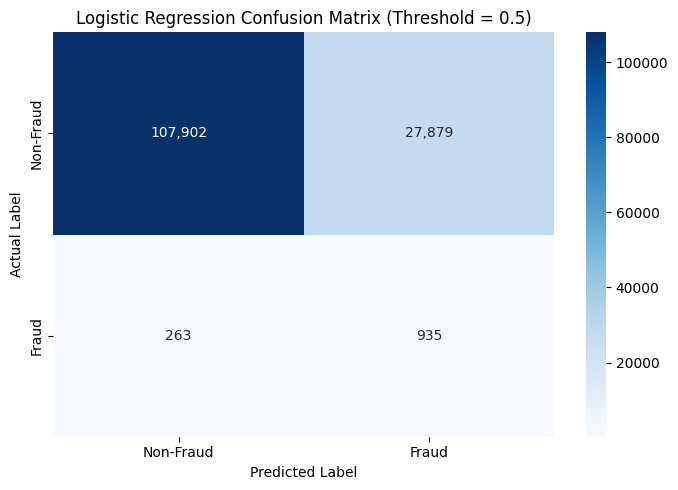

In [ ]:
logisticConfusionMatrix = confusion_matrix(
    yValidation,
    yValidationLogisticPrediction
)

tn, fp, fn, tp = logisticConfusionMatrix.ravel()

logisticConfusionSummary = pd.DataFrame({
    "metric": ["True Negative", "False Positive", "False Negative", "True Positive"],
    "count": [tn, fp, fn, tp]
})

print(logisticConfusionSummary.to_string(index=False))

plt.figure(figsize=(7, 5))

sns.heatmap(
    logisticConfusionMatrix,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title(f"Logistic Regression Confusion Matrix (Threshold = {logisticThreshold})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

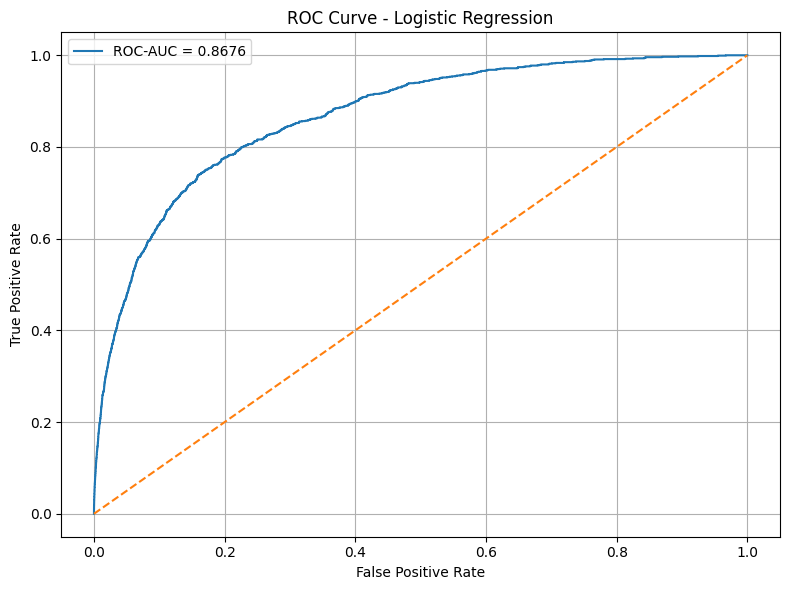

In [ ]:
logisticFalsePositiveRate, logisticTruePositiveRate, logisticThresholds = roc_curve(
    yValidation,
    yValidationLogisticProbability
)

plt.figure(figsize=(8, 6))

plt.plot(
    logisticFalsePositiveRate,
    logisticTruePositiveRate,
    label=f"ROC-AUC = {logisticRocAuc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 23. Train XGBoost Model

In [ ]:
negativeCount = (yTrain == 0).sum()
positiveCount = (yTrain == 1).sum()

scalePosWeight = negativeCount / positiveCount

print(f"Non-Fraud: {negativeCount}")
print(f"Fraud: {positiveCount}")
print(f"Scale Pos Weight: {scalePosWeight:.2f}")

Non-Fraud: 257362
Fraud: 2698
Scale Pos Weight: 95.39


In [ ]:
xgboostModel = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    scale_pos_weight=scalePosWeight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgboostModel.fit(XTrainTreeProcessed, yTrain)

print("XGBoost model training completed.")

XGBoost model training completed.


## 24. Evaluate XGBoost Model

In [ ]:
yValidationXGBoostProbability = xgboostModel.predict_proba(
    XValidationTreeProcessed
)[:, 1]

print(f"Validation predictions: {len(yValidationXGBoostProbability)}")
print(f"Minimum probability: {yValidationXGBoostProbability.min():.6f}")
print(f"Maximum probability: {yValidationXGBoostProbability.max():.6f}")

Validation predictions: 136979
Minimum probability: 0.000024
Maximum probability: 0.995841


In [ ]:
xgboostThreshold = 0.5

yValidationXGBoostPrediction = (
    yValidationXGBoostProbability >= xgboostThreshold
).astype(int)

print(f"Classification threshold: {xgboostThreshold}")
print(f"Predicted Non-Fraud: {(yValidationXGBoostPrediction == 0).sum()}")
print(f"Predicted Fraud: {(yValidationXGBoostPrediction == 1).sum()}")

Classification threshold: 0.5
Predicted Non-Fraud: 127505
Predicted Fraud: 9474


In [ ]:
xgboostRocAuc = roc_auc_score(yValidation, yValidationXGBoostProbability)
xgboostPrAuc = average_precision_score(yValidation, yValidationXGBoostProbability)

xgboostPrecision = precision_score(yValidation, yValidationXGBoostPrediction, zero_division=0)
xgboostRecall = recall_score(yValidation, yValidationXGBoostPrediction, zero_division=0)
xgboostF1 = f1_score(yValidation, yValidationXGBoostPrediction, zero_division=0)
xgboostAccuracy = accuracy_score(yValidation, yValidationXGBoostPrediction)

xgboostMetrics = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-Score",
        "Accuracy"
    ],
    "score": [
        xgboostRocAuc,
        xgboostPrAuc,
        xgboostPrecision,
        xgboostRecall,
        xgboostF1,
        xgboostAccuracy
    ]
})

xgboostMetrics["score"] = xgboostMetrics["score"].round(4)

print(xgboostMetrics.to_string(index=False))

   metric  score
  ROC-AUC 0.8616
   PR-AUC 0.1166
Precision 0.0667
   Recall 0.5275
 F1-Score 0.1184
 Accuracy 0.9313


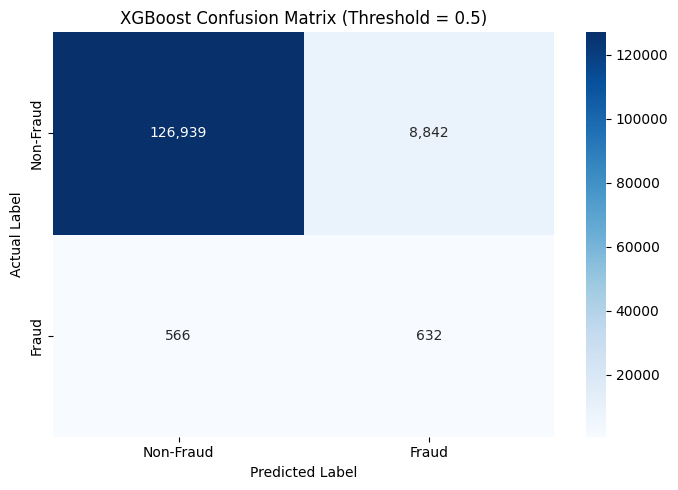

In [ ]:
xgboostConfusionMatrix = confusion_matrix(
    yValidation,
    yValidationXGBoostPrediction
)

tn, fp, fn, tp = xgboostConfusionMatrix.ravel()

xgboostConfusionSummary = pd.DataFrame({
    "metric": ["True Negative", "False Positive", "False Negative", "True Positive"],
    "count": [tn, fp, fn, tp]
})

print(xgboostConfusionSummary.to_string(index=False))

plt.figure(figsize=(7, 5))

sns.heatmap(
    xgboostConfusionMatrix,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title(f"XGBoost Confusion Matrix (Threshold = {xgboostThreshold})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

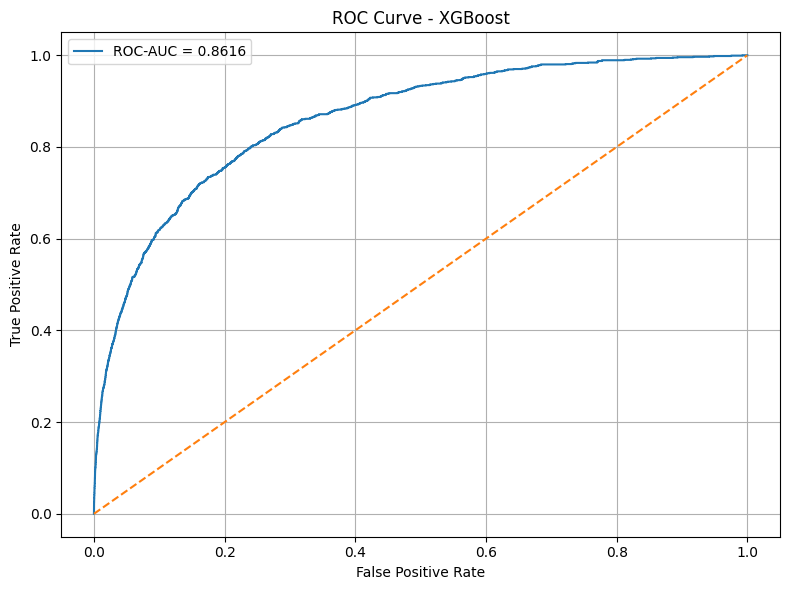

In [ ]:
xgboostFalsePositiveRate, xgboostTruePositiveRate, xgboostThresholds = roc_curve(
    yValidation,
    yValidationXGBoostProbability
)

plt.figure(figsize=(8, 6))

plt.plot(
    xgboostFalsePositiveRate,
    xgboostTruePositiveRate,
    label=f"ROC-AUC = {xgboostRocAuc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - XGBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 25. Compare baseline Models

In [120]:
logisticTN, logisticFP, logisticFN, logisticTP = logisticConfusionMatrix.ravel()
xgboostTN, xgboostFP, xgboostFN, xgboostTP = xgboostConfusionMatrix.ravel()

logisticFpr = logisticFP / (logisticFP + logisticTN)
logisticTpr = logisticTP / (logisticTP + logisticFN)

xgboostFpr = xgboostFP / (xgboostFP + xgboostTN)
xgboostTpr = xgboostTP / (xgboostTP + xgboostFN)

baselineComparison = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1-Score", "Accuracy", "FPR", "TPR"],
    "Logistic Regression": [
        logisticRocAuc,
        logisticPrAuc,
        logisticPrecision,
        logisticRecall,
        logisticF1,
        logisticAccuracy,
        logisticFpr,
        logisticTpr
    ],
    "XGBoost": [
        xgboostRocAuc,
        xgboostPrAuc,
        xgboostPrecision,
        xgboostRecall,
        xgboostF1,
        xgboostAccuracy,
        xgboostFpr,
        xgboostTpr
    ]
})

baselineComparison.iloc[:, 1:] = baselineComparison.iloc[:, 1:].round(4)

print(baselineComparison.to_string(index=False))

   metric  Logistic Regression  XGBoost
  ROC-AUC               0.8676   0.8616
   PR-AUC               0.1094   0.1166
Precision               0.0324   0.0667
   Recall               0.7805   0.5275
 F1-Score               0.0623   0.1184
 Accuracy               0.7946   0.9313
      FPR               0.2053   0.0651
      TPR               0.7805   0.5275


## 28. Hyperparameter Tuning Logistic Regression

In [156]:
def findOptimalThreshold(yTrue, yProbability, maxFpr=0.05):
    fpr, tpr, thresholds = roc_curve(yTrue, yProbability)

    validIndices = np.where(fpr <= maxFpr)[0]
    bestIndex = validIndices[np.argmax(tpr[validIndices])]

    return {
        "threshold": thresholds[bestIndex],
        "fpr": fpr[bestIndex],
        "tpr": tpr[bestIndex]
    }

 Target FPR  Threshold  Actual FPR    TPR
       0.01     0.5435      0.0100 0.2179
       0.02     0.4334      0.0198 0.3139
       0.03     0.3618      0.0298 0.3831
       0.04     0.3136      0.0400 0.4399
       0.05     0.2778      0.0499 0.4825


In [121]:
def logisticTprAtFivePercentFprScorer(estimator, X, y):
    yProbability = estimator.predict_proba(X)[:, 1]

    fpr, tpr, thresholds = roc_curve(y, yProbability)
    validIndices = np.where(fpr <= 0.05)[0]

    return float(np.max(tpr[validIndices]))

In [125]:
logisticTuningSplit = PredefinedSplit(
    test_fold=np.where(trainData["month"].to_numpy() == 1, 0, -1)
)

print("Training fold: Month 0")
print("Validation fold: Month 1")
print(f"Number of splits: {logisticTuningSplit.get_n_splits()}")

Training fold: Month 0
Validation fold: Month 1
Number of splits: 1


In [126]:
logisticPipeline = Pipeline(
    steps=[
        ("preprocessor", linearPreprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42,
            solver="lbfgs"
        ))
    ]
)

In [127]:
logisticParameterGrid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [
        "balanced",
        {0: 1, 1: 10},
        {0: 1, 1: 25},
        {0: 1, 1: 50},
        {0: 1, 1: 75},
        {0: 1, 1: 100}
    ]
}

In [128]:
logisticGridSearch = GridSearchCV(
    estimator=logisticPipeline,
    param_grid=logisticParameterGrid,
    scoring=logisticTprAtFivePercentFprScorer,
    cv=logisticTuningSplit,
    n_jobs=-1,
    verbose=1,
    refit=True,
    pre_dispatch=2
)

logisticGridSearch.fit(XTrain, yTrain)

print("Logistic Regression hyperparameter tuning completed.")
print("Best Parameters:")
print(logisticGridSearch.best_params_)
print(
    f"\nBest Cross-Validation TPR at FPR <= 5%: "
    f"{logisticGridSearch.best_score_:.4f}"
)

Fitting 1 folds for each of 36 candidates, totalling 36 fits
Logistic Regression hyperparameter tuning completed.
Best Parameters:
{'classifier__C': 0.01, 'classifier__class_weight': {0: 1, 1: 10}}

Best Cross-Validation TPR at FPR <= 5%: 0.4891


In [129]:
tunedLogisticModel = logisticGridSearch.best_estimator_

print("Best Logistic Regression model retrieved.")

Best Logistic Regression model retrieved.


In [130]:
yValidationTunedLogisticProbability = tunedLogisticModel.predict_proba(XValidation)[:, 1]

print(f"Validation predictions: {len(yValidationTunedLogisticProbability)}")
print(f"Minimum probability: {yValidationTunedLogisticProbability.min():.6f}")
print(f"Maximum probability: {yValidationTunedLogisticProbability.max():.6f}")

Validation predictions: 136979
Minimum probability: 0.000075
Maximum probability: 0.965426


In [161]:
tunedLogisticThresholdResults = {}

for targetFpr in [0.005, 0.0075, 0.01, 0.02, 0.03]:
    tunedLogisticThresholdResults[targetFpr] = findOptimalThreshold(
        yValidation,
        yValidationTunedLogisticProbability,
        maxFpr=targetFpr
    )

logisticThresholdComparison = pd.DataFrame([
    {
        "Target FPR": targetFpr,
        "Threshold": result["threshold"],
        "Actual FPR": result["fpr"],
        "TPR": result["tpr"]
    }
    for targetFpr, result in tunedLogisticThresholdResults.items()
])

print(logisticThresholdComparison.round(4).to_string(index=False))

 Target FPR  Threshold  Actual FPR    TPR
     0.0050     0.6382      0.0050 0.1469
     0.0075     0.5848      0.0075 0.1878
     0.0100     0.5435      0.0100 0.2179
     0.0200     0.4334      0.0198 0.3139
     0.0300     0.3618      0.0298 0.3831


In [163]:
tunedLogisticOptimalThreshold = tunedLogisticThresholdResults[0.02]
yValidationTunedLogisticPrediction = (
    yValidationTunedLogisticProbability >= tunedLogisticOptimalThreshold["threshold"]
).astype(int)

tunedLogisticConfusionMatrix = confusion_matrix(
    yValidation,
    yValidationTunedLogisticPrediction
)

tunedLogisticTN, tunedLogisticFP, tunedLogisticFN, tunedLogisticTP = (
    tunedLogisticConfusionMatrix.ravel()
)

tunedLogisticPrecision = precision_score(
    yValidation,
    yValidationTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticRecall = recall_score(
    yValidation,
    yValidationTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticF1 = f1_score(
    yValidation,
    yValidationTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticFpr = tunedLogisticFP / (tunedLogisticFP + tunedLogisticTN)
tunedLogisticTpr = tunedLogisticTP / (tunedLogisticTP + tunedLogisticFN)

print(f"Threshold: {tunedLogisticOptimalThreshold['threshold']:.6f}")
print(f"Precision: {tunedLogisticPrecision:.4f}")
print(f"Recall: {tunedLogisticRecall:.4f}")
print(f"F1-Score: {tunedLogisticF1:.4f}")
print(f"FPR: {tunedLogisticFpr:.4f}")
print(f"TPR: {tunedLogisticTpr:.4f}")

print("\nConfusion Matrix:")
print(tunedLogisticConfusionMatrix)

Threshold: 0.433398
Precision: 0.1228
Recall: 0.3139
F1-Score: 0.1765
FPR: 0.0198
TPR: 0.3139

Confusion Matrix:
[[133094   2687]
 [   822    376]]


## 29. Hyperparameter Tuning XGBoost

In [134]:
def xgboostTprAtFivePercentFprScorer(estimator, X, y):
    yProbability = estimator.predict_proba(X)[:, 1]

    fpr, tpr, thresholds = roc_curve(y, yProbability)
    validIndices = np.where(fpr <= 0.05)[0]

    return float(np.max(tpr[validIndices]))

In [135]:
xgboostTuningSplit = PredefinedSplit(
    test_fold=np.where(trainData["month"].to_numpy() == 1, 0, -1)
)

print("Training fold: Month 0")
print("Validation fold: Month 1")
print(f"Number of splits: {xgboostTuningSplit.get_n_splits()}")

Training fold: Month 0
Validation fold: Month 1
Number of splits: 1


In [136]:
xgboostPipeline = Pipeline(
    steps=[
        ("preprocessor", treePreprocessor),
        ("classifier", XGBClassifier(
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            random_state=42,
            n_jobs=1
        ))
    ]
)

In [137]:
xgboostParameterGrid = {
    "classifier__n_estimators": [300, 500],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__min_child_weight": [5, 10],
    "classifier__scale_pos_weight": [50, scalePosWeight]
}

In [144]:
xgboostGridSearch = GridSearchCV(
    estimator=xgboostPipeline,
    param_grid=xgboostParameterGrid,
    scoring=xgboostTprAtFivePercentFprScorer,
    cv=xgboostTuningSplit,
    n_jobs=-1,
    verbose=1,
    refit=True,
    pre_dispatch=2
)

xgboostGridSearch.fit(XTrain, yTrain)

print("XGBoost hyperparameter tuning completed.")


Fitting 1 folds for each of 32 candidates, totalling 32 fits
XGBoost hyperparameter tuning completed.


In [145]:
tunedXgboostModel = xgboostGridSearch.best_estimator_

print(type(tunedXgboostModel))
print("Best XGBoost model retrieved.")

<class 'sklearn.pipeline.Pipeline'>
Best XGBoost model retrieved.


In [146]:
yValidationTunedXgboostProbability = tunedXgboostModel.predict_proba(XValidation)[:, 1]

print(f"Validation predictions: {len(yValidationTunedXgboostProbability)}")
print(f"Minimum probability: {yValidationTunedXgboostProbability.min():.6f}")
print(f"Maximum probability: {yValidationTunedXgboostProbability.max():.6f}")

Validation predictions: 136979
Minimum probability: 0.001546
Maximum probability: 0.987985


In [160]:
tunedXgboostThresholdResults = {}

for targetFpr in [0.005, 0.0075, 0.01, 0.02, 0.03]:
    tunedXgboostThresholdResults[targetFpr] = findOptimalThreshold(
        yValidation,
        yValidationTunedXgboostProbability,
        maxFpr=targetFpr
    )

xgboostThresholdComparison = pd.DataFrame([
    {
        "Target FPR": targetFpr,
        "Threshold": result["threshold"],
        "Actual FPR": result["fpr"],
        "TPR": result["tpr"]
    }
    for targetFpr, result in tunedXgboostThresholdResults.items()
])

print(xgboostThresholdComparison.round(4).to_string(index=False))

 Target FPR  Threshold  Actual FPR    TPR
     0.0050     0.8726      0.0049 0.1811
     0.0075     0.8459      0.0075 0.2137
     0.0100     0.8241      0.0100 0.2471
     0.0200     0.7485      0.0198 0.3389
     0.0300     0.6927      0.0299 0.4432


In [164]:
tunedXgboostOptimalThreshold = tunedXgboostThresholdResults[0.02]
yValidationTunedXgboostPrediction = (
    yValidationTunedXgboostProbability >= tunedXgboostOptimalThreshold["threshold"]
).astype(int)

tunedXgboostConfusionMatrix = confusion_matrix(
    yValidation,
    yValidationTunedXgboostPrediction
)

tunedXgboostTN, tunedXgboostFP, tunedXgboostFN, tunedXgboostTP = (
    tunedXgboostConfusionMatrix.ravel()
)

tunedXgboostPrecision = precision_score(
    yValidation,
    yValidationTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostRecall = recall_score(
    yValidation,
    yValidationTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostF1 = f1_score(
    yValidation,
    yValidationTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostFpr = tunedXgboostFP / (tunedXgboostFP + tunedXgboostTN)
tunedXgboostTpr = tunedXgboostTP / (tunedXgboostTP + tunedXgboostFN)

print(f"Threshold: {tunedXgboostOptimalThreshold['threshold']:.6f}")
print(f"Precision: {tunedXgboostPrecision:.4f}")
print(f"Recall: {tunedXgboostRecall:.4f}")
print(f"F1-Score: {tunedXgboostF1:.4f}")
print(f"FPR: {tunedXgboostFpr:.4f}")
print(f"TPR: {tunedXgboostTpr:.4f}")

print("\nConfusion Matrix:")
print(tunedXgboostConfusionMatrix)

Threshold: 0.748545
Precision: 0.1310
Recall: 0.3389
F1-Score: 0.1889
FPR: 0.0198
TPR: 0.3389

Confusion Matrix:
[[133087   2694]
 [   792    406]]


## 30. Compare Tuned Models

In [165]:
tunedModelComparison = pd.DataFrame({
    "metric": ["Threshold", "Precision", "Recall", "F1-Score", "FPR", "TPR"],
    "Logistic Regression": [
        tunedLogisticOptimalThreshold["threshold"],
        tunedLogisticPrecision,
        tunedLogisticRecall,
        tunedLogisticF1,
        tunedLogisticFpr,
        tunedLogisticTpr
    ],
    "XGBoost": [
        tunedXgboostOptimalThreshold["threshold"],
        tunedXgboostPrecision,
        tunedXgboostRecall,
        tunedXgboostF1,
        tunedXgboostFpr,
        tunedXgboostTpr
    ]
})

tunedModelComparison.iloc[:, 1:] = tunedModelComparison.iloc[:, 1:].round(4)

print(tunedModelComparison.to_string(index=False))

   metric  Logistic Regression  XGBoost
Threshold               0.4334   0.7485
Precision               0.1228   0.1310
   Recall               0.3139   0.3389
 F1-Score               0.1765   0.1889
      FPR               0.0198   0.0198
      TPR               0.3139   0.3389


## 31. Final Evaluation on Test Set

In [166]:
yTestTunedLogisticProbability = tunedLogisticModel.predict_proba(XTest)[:, 1]
yTestTunedXgboostProbability = tunedXgboostModel.predict_proba(XTest)[:, 1]

yTestTunedLogisticPrediction = (
    yTestTunedLogisticProbability >= tunedLogisticOptimalThreshold["threshold"]
).astype(int)

yTestTunedXgboostPrediction = (
    yTestTunedXgboostProbability >= tunedXgboostOptimalThreshold["threshold"]
).astype(int)

print(f"Test samples: {len(yTest)}")
print(f"Actual Fraud: {(yTest == 1).sum()}")
print(f"Actual Non-Fraud: {(yTest == 0).sum()}")

print("\nLogistic Regression Predictions")
print(f"Predicted Fraud: {yTestTunedLogisticPrediction.sum()}")
print(f"Predicted Non-Fraud: {(yTestTunedLogisticPrediction == 0).sum()}")

print("\nXGBoost Predictions")
print(f"Predicted Fraud: {yTestTunedXgboostPrediction.sum()}")
print(f"Predicted Non-Fraud: {(yTestTunedXgboostPrediction == 0).sum()}")

Test samples: 150936
Actual Fraud: 1392
Actual Non-Fraud: 149544

Logistic Regression Predictions
Predicted Fraud: 6178
Predicted Non-Fraud: 144758

XGBoost Predictions
Predicted Fraud: 7130
Predicted Non-Fraud: 143806


In [167]:
tunedLogisticTestConfusionMatrix = confusion_matrix(
    yTest,
    yTestTunedLogisticPrediction
)

tunedLogisticTestTN, tunedLogisticTestFP, tunedLogisticTestFN, tunedLogisticTestTP = (
    tunedLogisticTestConfusionMatrix.ravel()
)

tunedLogisticTestPrecision = precision_score(
    yTest,
    yTestTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticTestRecall = recall_score(
    yTest,
    yTestTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticTestF1 = f1_score(
    yTest,
    yTestTunedLogisticPrediction,
    zero_division=0
)

tunedLogisticTestFpr = tunedLogisticTestFP / (
    tunedLogisticTestFP + tunedLogisticTestTN
)

tunedLogisticTestTpr = tunedLogisticTestTP / (
    tunedLogisticTestTP + tunedLogisticTestFN
)

tunedLogisticTestRocAuc = roc_auc_score(
    yTest,
    yTestTunedLogisticProbability
)

tunedLogisticTestPrAuc = average_precision_score(
    yTest,
    yTestTunedLogisticProbability
)

print("Logistic Regression - Test Set")
print(f"ROC-AUC: {tunedLogisticTestRocAuc:.4f}")
print(f"PR-AUC: {tunedLogisticTestPrAuc:.4f}")
print(f"Precision: {tunedLogisticTestPrecision:.4f}")
print(f"Recall: {tunedLogisticTestRecall:.4f}")
print(f"F1-Score: {tunedLogisticTestF1:.4f}")
print(f"FPR: {tunedLogisticTestFpr:.4f}")
print(f"TPR: {tunedLogisticTestTpr:.4f}")
print("\nConfusion Matrix:")
print(tunedLogisticTestConfusionMatrix)

Logistic Regression - Test Set
ROC-AUC: 0.8926
PR-AUC: 0.1298
Precision: 0.1010
Recall: 0.4483
F1-Score: 0.1649
FPR: 0.0371
TPR: 0.4483

Confusion Matrix:
[[143990   5554]
 [   768    624]]


In [168]:
tunedXgboostTestConfusionMatrix = confusion_matrix(
    yTest,
    yTestTunedXgboostPrediction
)

tunedXgboostTestTN, tunedXgboostTestFP, tunedXgboostTestFN, tunedXgboostTestTP = (
    tunedXgboostTestConfusionMatrix.ravel()
)

tunedXgboostTestPrecision = precision_score(
    yTest,
    yTestTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostTestRecall = recall_score(
    yTest,
    yTestTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostTestF1 = f1_score(
    yTest,
    yTestTunedXgboostPrediction,
    zero_division=0
)

tunedXgboostTestFpr = tunedXgboostTestFP / (
    tunedXgboostTestFP + tunedXgboostTestTN
)

tunedXgboostTestTpr = tunedXgboostTestTP / (
    tunedXgboostTestTP + tunedXgboostTestFN
)

tunedXgboostTestRocAuc = roc_auc_score(
    yTest,
    yTestTunedXgboostProbability
)

tunedXgboostTestPrAuc = average_precision_score(
    yTest,
    yTestTunedXgboostProbability
)

print("XGBoost - Test Set")
print(f"ROC-AUC: {tunedXgboostTestRocAuc:.4f}")
print(f"PR-AUC: {tunedXgboostTestPrAuc:.4f}")
print(f"Precision: {tunedXgboostTestPrecision:.4f}")
print(f"Recall: {tunedXgboostTestRecall:.4f}")
print(f"F1-Score: {tunedXgboostTestF1:.4f}")
print(f"FPR: {tunedXgboostTestFpr:.4f}")
print(f"TPR: {tunedXgboostTestTpr:.4f}")
print("\nConfusion Matrix:")
print(tunedXgboostTestConfusionMatrix)

XGBoost - Test Set
ROC-AUC: 0.9134
PR-AUC: 0.1601
Precision: 0.1059
Recall: 0.5424
F1-Score: 0.1772
FPR: 0.0426
TPR: 0.5424

Confusion Matrix:
[[143169   6375]
 [   637    755]]


In [170]:
finalTestComparison = pd.DataFrame({
    "metric": [
        "Threshold",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1-Score",
        "FPR",
        "TPR"
    ],
    "Logistic Regression": [
        tunedLogisticOptimalThreshold["threshold"],
        tunedLogisticTestRocAuc,
        tunedLogisticTestPrAuc,
        tunedLogisticTestPrecision,
        tunedLogisticTestRecall,
        tunedLogisticTestF1,
        tunedLogisticTestFpr,
        tunedLogisticTestTpr
    ],
    "XGBoost": [
        tunedXgboostOptimalThreshold["threshold"],
        tunedXgboostTestRocAuc,
        tunedXgboostTestPrAuc,
        tunedXgboostTestPrecision,
        tunedXgboostTestRecall,
        tunedXgboostTestF1,
        tunedXgboostTestFpr,
        tunedXgboostTestTpr
    ]
})

finalTestComparison.iloc[:, 1:] = finalTestComparison.iloc[:, 1:].round(4)

print(finalTestComparison.to_string(index=False))

   metric  Logistic Regression  XGBoost
Threshold               0.4334   0.7485
  ROC-AUC               0.8926   0.9134
   PR-AUC               0.1298   0.1601
Precision               0.1010   0.1059
   Recall               0.4483   0.5424
 F1-Score               0.1649   0.1772
      FPR               0.0371   0.0426
      TPR               0.4483   0.5424


Berdasarkan hasil evaluasi pada test set, **XGBoost dipilih sebagai model terbaik** dengan threshold 0.7485. Model ini menghasilkan ROC-AUC 0.9134, PR-AUC 0.1601, precision 10.59%, recall 54.24%, dan F1-Score 17.72%, dengan FPR sebesar 4.26%.

Sementara itu, Logistic Regression menghasilkan FPR 3.71% dan TPR 44.83%. Kedua model memenuhi requirement FPR maksimal 5%, tetapi XGBoost mampu mendeteksi lebih banyak aplikasi fraud dengan TPR lebih tinggi, yaitu 54.24%.

## 32. Export Final Model

In [172]:
finalModel = {
    "model": tunedXgboostModel,
    "modelName": "XGBoost",
    "threshold": tunedXgboostOptimalThreshold["threshold"],
    "featureColumns": featureColumns,
    "targetColumn": targetColumn
}

modelFilePath = "bankFraudXgboostModel.joblib"

joblib.dump(finalModel, modelFilePath, compress=3)

print(f"Model successfully exported: {Path(modelFilePath).resolve()}")
print(f"Model: {finalModel['modelName']}")
print(f"Threshold: {finalModel['threshold']:.6f}")
print(f"Number of Features: {len(finalModel['featureColumns'])}")

Model successfully exported: /content/bankFraudXgboostModel.joblib
Model: XGBoost
Threshold: 0.748545
Number of Features: 29
